# Predicting Property Prices


## Import Libraries


In [1]:
# import libraries
import pandas as pd
import plotly.express as px
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import geopandas as gpd
from shapely.geometry import shape
import requests
import time
import warnings
import os
import glob
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold, GridSearchCV
from xgboost import XGBRegressor
from sklearn.metrics import make_scorer, mean_absolute_error, mean_squared_error, r2_score
import pickle

KeyboardInterrupt: 

In [2]:
warnings.filterwarnings('ignore')

## Prepare Data


### Utility Variables


In [3]:
# relevant area codes
area_codes = [
    'E08000011', 'E08000012', 'E11000002', 'E08000014', 'E08000013',
    'E08000007', 'E06000007', 'E08000010', 'E08000015'
]

# Regions in Merseyside
regions = [
    'Prenton', 'Newton-Le-Willows', 'Birkenhead',
    'Wirral', 'Bootle', 'St Helens', 'Wallasey', 'Southport',
    'Prescot', 'Wigan', 'Widnes', 'Neston', 'Warrington',
    'Ellesmere Port', 'Wilmslow', 'Coniston', 'Stockport', 'Northwood',
    'Crewe', 'Winsford', 'Merseyside', 'Sefton', 'Wirral', 'Liverpool', 'Knowsley'
]

### Utility Functions


In [4]:
def standardise_column(df, column_name, mapping, remove_values=None, new_dtype='category'):
    """
    Standardise a DataFrame column by applying a mapping, optionally removing specific values, 
    and changing the data type.

    Parameters:
    df (DataFrame): The input DataFrame.
    column_name (str): The name of the column to standardize.
    mapping (dict): A dictionary mapping old values to new values.
    remove_values (list, optional): A list of values to remove from the column. Default is None.
    new_dtype (str, optional): The new data type for the column. Default is 'category'.

    Returns:
    DataFrame: The DataFrame with the standardized column.
    """

    # Optionally remove rows with specific values
    if remove_values:
        df = df[~df[column_name].isin(remove_values)]

    # Apply the mapping to replace old values with new values
    df[column_name] = df[column_name].replace(mapping).astype(new_dtype)

    return df

In [5]:
def rename_columns(df, new_column_names):
    """
    Rename the columns of a DataFrame using a provided list of new column names.

    Parameters:
    df (DataFrame): The input DataFrame whose columns need to be renamed.
    new_column_names (list): A list of new column names.

    Returns:
    DataFrame: The DataFrame with renamed columns.
    """
    # Check if the number of new column names matches the number of columns in the DataFrame
    if len(new_column_names) != df.shape[1]:
        raise ValueError(
            "The number of new column names must match the number of columns in the DataFrame.")

    # Rename the columns
    df.columns = new_column_names

    return df

### Import


#### Prices Paid Data


In [6]:
def bulk_lookup_postcodes(postcodes, batch_size=100):
    """
    Perform a bulk lookup for postcodes using the postcodes.io API.

    Parameters:
    postcodes (list): A list of postcodes to lookup.
    batch_size (int): The number of postcodes to include in each batch (max 100).

    Returns:
    dict: A dictionary mapping postcodes to their respective data, including latitude, longitude, and termination data if applicable.
    """
    url = "https://api.postcodes.io/postcodes"
    headers = {'Content-Type': 'application/json'}
    results = {}

    # Process the postcodes in batches
    for i in range(0, len(postcodes), batch_size):
        batch = postcodes[i:i+batch_size]
        data = {"postcodes": batch}

        response = requests.post(url, json=data, headers=headers)

        if response.status_code == 200:
            response_data = response.json()
            for result in response_data['result']:
                postcode = result['query']
                if result['result'] is not None:
                    results[postcode] = {
                        'longitude': result['result']['longitude'],
                        'latitude': result['result']['latitude'],
                        'is_terminated': False
                    }
                else:
                    # If the postcode is terminated, set to None and mark as terminated
                    results[postcode] = {
                        'longitude': None,
                        'latitude': None,
                        'is_terminated': True
                    }
        else:
            print(
                f"Failed to retrieve data for batch starting at {i}: {response.status_code}")
        time.sleep(0.1)  # To avoid rate limiting

    return results

In [7]:

def handle_terminated_postcodes(postcode_data):
    """
    Handle postcodes that are marked as terminated by checking the terminated postcode API.

    Parameters:
    postcode_data (dict): A dictionary of postcodes with their data, including termination status.

    Returns:
    dict: Updated dictionary with longitude and latitude for terminated postcodes if available.
    """
    terminated_postcodes = [postcode for postcode,
                            data in postcode_data.items() if data['is_terminated']]

    if not terminated_postcodes:
        return postcode_data  # No terminated postcodes to handle

    # Query terminated postcodes in bulk (max 100 at a time)
    url = "https://api.postcodes.io/terminated_postcodes"
    headers = {'Content-Type': 'application/json'}
    batch_size = 100

    for i in range(0, len(terminated_postcodes), batch_size):
        batch = terminated_postcodes[i:i+batch_size]
        data = {"postcodes": batch}

        response = requests.post(url, json=data, headers=headers)

        if response.status_code == 200:
            response_data = response.json()
            for result in response_data['result']:
                postcode = result['query']
                if result['result'] is not None:
                    postcode_data[postcode]['longitude'] = result['result']['longitude']
                    postcode_data[postcode]['latitude'] = result['result']['latitude']
                else:
                    # print(f"No data found for terminated postcode: {postcode}")
                    continue
        else:
            # print(
            #     f"Failed to retrieve data for terminated postcodes batch starting at {i}: {response.status_code}")
            continue
        time.sleep(0.1)  # To avoid rate limiting

    return postcode_data

In [8]:
def add_long_lat_columns(df, postcode_column='postcode'):
    """
    Add longitude and latitude columns to the DataFrame based on the postcode column using Bulk Lookup.

    Parameters:
    df (DataFrame): The input DataFrame with a postcode column.
    postcode_column (str): The name of the column containing postcodes. Default is 'postcode'.

    Returns:
    DataFrame: The DataFrame with added 'longitude' and 'latitude' columns.
    """
    postcodes = df[postcode_column].unique().tolist()
    postcode_data = bulk_lookup_postcodes(postcodes)
    postcode_data = handle_terminated_postcodes(postcode_data)

    # Map the longitude and latitude back to the original DataFrame
    df['longitude'] = df[postcode_column].map(
        lambda x: postcode_data[x]['longitude'])
    df['latitude'] = df[postcode_column].map(
        lambda x: postcode_data[x]['latitude'])

    return df

In [9]:
# define wrangle function for prices paid data
def wrangle_prices_paid(filepath):

    # import file
    df = pd.read_csv(filepath)

    # drop complete duplicates from house_data
    df = df.drop_duplicates()

    # add column names to df
    column_names = [
        'transaction_id', 'price', 'transfer_date',
        'postcode', 'property_type', 'is_old_or_new',
        'property_tenure', 'house_number_or_name', 'unit_number',
        'street', 'locality', 'town', 'district', 'county',
        'ppd_transaction_category', 'record_status_monthly_file_only'
    ]
    df = rename_columns(df, column_names)
    
    # convert transfer date to datetime
    df['transfer_date'] = pd.to_datetime(df['transfer_date'])
    
    # sort data by teansaction date
    df = df.sort_values('transfer_date', ascending=True)
    
    # filter data for freehold transactions in merseyside from 2013 to 2023
    df = df[(df['county'] == 'MERSEYSIDE') & (
        df['transfer_date'].dt.year >= 2013) & (df['transfer_date'].dt.year <= 2023)]

    # convert price to float type
    df['price'] = df['price'].astype(float)
    
    # remove outliers in price by values in the bottom and top 5% of properties
    low, high = df['price'].quantile([0.05, 0.95])
    mask_area = df['price'].between(low, high)
    df = df[mask_area]

    # convert ppd_transaction_category to category type
    df['ppd_transaction_category'] = df['ppd_transaction_category'].astype(
        'category')

    # define mappings for replacement
    property_type_mapping = {'T': 'Terraced', 'D': 'Detached', 'F': 'Flats/Maisonettes',
                             'S': 'Semi-Detached', 'O': 'Other'}
    old_or_new_mapping = {'N': 'Old', 'Y': 'New'}
    property_tenure_mapping = {'F': 'Freehold', 'L': 'Leasehold'}

    # standardize 'property_type' column
    df = standardise_column(df, 'property_type', property_type_mapping)
    # standardize 'is_old_or_new' column
    df = standardise_column(df, 'is_old_or_new', old_or_new_mapping)
    # standardize 'property_tenure' column and remove rows with 'U' before standardising
    df = standardise_column(df, 'property_tenure',
                            property_tenure_mapping, remove_values=['U'])

    # convert capital case columns to title case
    df['town'] = df['town'].str.title()
    df['district'] = df['district'].str.title()
    df['county'] = df['county'].str.title()
    
    # exclude rows with null postcode values
    df = df[~df['postcode'].isnull()]
    
    # created latitude and longitude columns
    df = add_long_lat_columns(df)

    # drop redundant columns
    df.drop(columns=['house_number_or_name', 'unit_number', 'locality',
                     'street', 'record_status_monthly_file_only', 'postcode'],
            inplace=True
            )

    return df

In [10]:
# Wrangle the prices paid data
prices_paid_data_df = wrangle_prices_paid(
    filepath="raw_data/prices_paid.csv")

# Display the first few rows to verify
prices_paid_data_df.head()

,transaction_id,price,transfer_date,property_type,is_old_or_new,property_tenure,town,district,county,ppd_transaction_category,longitude,latitude
18351985,{EF89E3A8-2BD1-4347-8B9B-F2CEEB2E62DC},75000.0,2013-01-02,Flats/Maisonettes,Old,Leasehold,Prenton,Wirral,Merseyside,A,-3.038801,53.384498
18251630,{CD1FD346-02E2-40B9-AD20-AF02A78999D1},113000.0,2013-01-02,Semi-Detached,Old,Freehold,Liverpool,Sefton,Merseyside,A,-2.946158,53.519373
18458777,{3008D681-978E-4FB2-B152-5077F80C64CF},79500.0,2013-01-02,Terraced,Old,Freehold,Birkenhead,Wirral,Merseyside,A,-3.019912,53.376715
18512520,{554C7E6D-FB60-4BF3-AEF0-F18802D4C110},385000.0,2013-01-02,Detached,Old,Freehold,Newton-Le-Willows,St Helens,Merseyside,A,-2.635595,53.479038
18275462,{3A27DE8C-0D42-41CC-8501-7367F7E98993},115000.0,2013-01-02,Semi-Detached,Old,Freehold,Liverpool,Liverpool,Merseyside,A,-2.904433,53.412073


#### Employment Data


In [11]:
# define wrangle function for employment data
def wrangle_employment(filepath):

    # import file
    df = pd.read_csv(filepath)

    # add column names to df
    column_names = ['area_code', 'area_name', 'year', 'employment_rate',
                    'confidence_interval_lower', 'confidence_interval_upper']
    df = rename_columns(df, column_names)
    
    # filter for employment rate from 2013 to 2023
    df = df[(df['year'] >= 2013) & (df['year'] <= 2023)]

    # relevant columns
    relevant_columns = ['area_code', 'area_name', 'year', 'employment_rate']
    # select relevant columns
    df = df[relevant_columns]

    # filter for relevant area codes and names
    df = df[(df['area_name'].isin(
        regions)) | (df['area_code'].isin(
            area_codes))].sort_values('year')
    
    # Convert the year column to string, then to datetime
    df['year'] = df['year'].astype(str)
    df['year'] = pd.to_datetime(
        df['year'], format='%Y')
    # to keep only the year part
    df['year'] = df['year'].dt.year
        
    # Convert employment rate from percentatage to rates
    df['employment_rate'] = df['employment_rate']/100
    
    # aggregate the data
    df = df.groupby(['area_code', 'area_name', 'year']).agg({
        'employment_rate': 'mean'
    }).reset_index()
    
    # drop rows with any missing values
    df = df.dropna()
    
    return df

In [12]:
# Wrangle the employment data
employment_data_df = wrangle_employment(filepath="raw_data/employment_data.csv")

# Display the first few rows to verify
employment_data_df.head()

,area_code,area_name,year,employment_rate
0,E06000007,Warrington,2013,0.782
1,E06000007,Warrington,2014,0.779
2,E06000007,Warrington,2015,0.779
3,E06000007,Warrington,2016,0.762
4,E06000007,Warrington,2017,0.774


#### UK HPI Data

In [13]:
# define wrangle function for hpi data
def wrangle_hpi(filepath):

    # import file
    df = pd.read_csv(filepath)
    
    # select relevant columns
    relevant_columns = [
        'Date', 'RegionName', 'AreaCode', 'AveragePrice', 'Index', '1m%Change', '12m%Change', 'SalesVolume'
    ]
    df = df[relevant_columns]
    
    # change column names
    column_names = ['date', 'region_name', 'area_code', 'average_price',
                    'index', '1m%_change', '12m%_change', 'sales_volume']
    df = rename_columns(df, column_names)
    
    # change date to dattime instead of object
    df['date'] = pd.to_datetime(df['date'])
    
    # Filter for the date range
    df = df[(df['date'] >= '2013-01-01') & (
        df['date'] <= '2023-12-31')]
    
    # filter for relevant area codes and names
    df = df[(df['region_name'].isin(
        regions)) | (df['area_code'].isin(
            area_codes))].sort_values('date')
    
    # drop complete duplicates
    df = df.drop_duplicates()
    
    # drop rows with any missing values
    df = df.dropna()
    
    return df

In [14]:
# Wrangle the HPI data
hpi_data_df = wrangle_hpi(filepath="raw_data/uk_hpi.csv")

# Display the first few rows to verify
hpi_data_df.head()

,date,region_name,area_code,average_price,index,1m%_change,12m%_change,sales_volume
86092,2013-01-01,Knowsley,E08000011,105390.6729,97.958916,0.304925,-1.857656,67.0
86105,2013-01-01,Liverpool,E08000012,105140.5433,93.986552,-0.314031,-2.003400,292.0
86115,2013-01-01,Merseyside,E11000002,118307.7900,95.814439,-0.183908,-1.070033,891.0
86196,2013-01-01,Sefton,E08000014,135940.7468,98.603056,0.431996,-0.460236,176.0
86225,2013-01-01,St Helens,E08000013,107387.2971,96.951534,0.002608,0.660812,103.0


#### Income Data

In [15]:
# define wrangle function for hpi data
def wrangle_income(filepath):

    # import file
    df = pd.read_csv(filepath)
    
    # change column names
    column_names = ['area_code', 'area_name', 'year',
                        'gross_median_weekly_pay', 'confidence_interval_lower', 'confidence_interval_upper']
    df = rename_columns(df, column_names)
    

    # relevant columns
    relevant_columns = ['area_code', 'area_name',
                        'year', 'gross_median_weekly_pay']
    # select relevant columns
    df = df[relevant_columns]
    
    
    # Convert the year column to string, then to datetime
    df['year'] = df['year'].astype(str)
    df['year'] = pd.to_datetime(
        df['year'], format='%Y')

    # to keep only the year part
    df['year'] = df['year'].dt.year

    # filter for relevant area codes and names
    df = df[(df['area_name'].isin(
        regions)) | (df['area_code'].isin(
            area_codes))].sort_values('year')
    
    # aggregate the data
    df = df.groupby(['area_code', 'area_name', 'year']).agg({
        'gross_median_weekly_pay': 'mean'
    }).reset_index()

    # drop rows with any missing values
    df = df.dropna()
    
    return df

In [16]:
# Wrangle the income data
income_data_df = wrangle_income(filepath= "raw_data/income_data.csv")

# Display the first few rows to verify
income_data_df.head()

,area_code,area_name,year,gross_median_weekly_pay
0,E06000007,Warrington,2008,410.2
1,E06000007,Warrington,2009,424.2
2,E06000007,Warrington,2010,428.5
3,E06000007,Warrington,2011,402.7
4,E06000007,Warrington,2012,411.8


#### Crime Data

In [17]:
def merge_csv_files_in_folder(folder_path, pattern='*.csv'):
    """
    Merge all CSV files in a given folder into a single DataFrame.

    Parameters:
    folder_path (str): The path to the folder containing the CSV files.
    pattern (str): The pattern to match CSV files in the folder. Default is '*.csv'.

    Returns:
    DataFrame: A merged DataFrame containing all the data from the CSV files.
    """
    # Initialize an empty list to store DataFrames
    df_list = []

    # Get a list of all CSV files in the folder that match the pattern
    csv_files = glob.glob(os.path.join(folder_path, pattern))

    # Iterate over the list of files and read each one into a DataFrame
    for file in csv_files:
        df = pd.read_csv(file)
        df_list.append(df)

    # Concatenate all DataFrames into a single DataFrame
    merged_df = pd.concat(df_list, ignore_index=True)

    return merged_df

merged_crime_data = merge_csv_files_in_folder('raw_data/merseyside_csv_files')

# Display the first few rows to verify the merged data
merged_crime_data.head()

,Crime ID,Month,Reported by,Falls within,Longitude,Latitude,Location,LSOA code,LSOA name,Crime type,Last outcome category,Context
0,02bc77633b1f2f795a1776f92a20304619bb73ee60cb36...,2019-11,Merseyside Police,Merseyside Police,-2.797801,53.355197,On or near Lower Road,E01012391,Halton 008B,Vehicle crime,Unable to prosecute suspect,NaN
1,NaN,2019-11,Merseyside Police,Merseyside Police,-2.875002,53.486621,On or near Bigdale Drive,E01006448,Knowsley 001A,Anti-social behaviour,NaN,NaN
2,NaN,2019-11,Merseyside Police,Merseyside Police,-2.849802,53.490299,On or near Depot Road,E01006448,Knowsley 001A,Anti-social behaviour,NaN,NaN
3,NaN,2019-11,Merseyside Police,Merseyside Police,-2.872082,53.487541,On or near Quernmore Road,E01006448,Knowsley 001A,Anti-social behaviour,NaN,NaN
4,NaN,2019-11,Merseyside Police,Merseyside Police,-2.871609,53.489432,On or near Watts Close,E01006448,Knowsley 001A,Anti-social behaviour,NaN,NaN


In [18]:
def wrangle_crime_data(df):
    """
    Cleans and processes crime data by selecting relevant columns, 
    converting the 'Month' to datetime, and sorting by 'Month'.
    
    Parameters:
    df (DataFrame): The input DataFrame containing raw crime data.
    
    Returns:
    DataFrame: A cleaned DataFrame containing only relevant columns.
    """
    # Select relevant columns
    df = df[['Month', 'Longitude', 'Latitude', 'Crime type']]

    # Convert 'Month' to datetime
    df['Month'] = pd.to_datetime(df['Month'], format='%Y-%m').dt.to_period('M')

    # Sort the DataFrame by 'Month'
    df = df.sort_values(by='Month', ascending=True)
    
    
    
    
    # Reduce multicolinearity
    # define mappings for replacement
    crime_type_mapping = {
        'Violence and sexual offences': 'violent_crime',
        'Robbery': 'violent_crime',
        'Possession of weapons': 'violent_crime',
        'Violent crime': 'violent_crime',
        'Burglary': 'property_crime',
        'Vehicle crime': 'property_crime',
        'Shoplifting': 'property_crime',
        'Other theft': 'property_crime',
        'Theft from the person': 'property_crime',
        'Anti-social behaviour': 'anti_social_behavior',
        'Public order': 'anti_social_behavior',
        'Criminal damage and arson': 'anti_social_behavior',
        'Public disorder and weapons': 'anti_social_behavior',
        'Drugs': 'drug_related_crime',
        'Other crime': 'minor_misc_crime',
        'Bicycle theft': 'minor_misc_crime'
        }

    # standardize 'Crime type' column
    df = standardise_column(df, 'Crime type', crime_type_mapping)

    # Optionally, rename the columns for clarity
    df = df.rename(
        columns={'Month': 'crime_date', 'Crime type': 'crime', 'Longitude': 'long', 'Latitude': 'lat'})

    return df

crime_data_df = wrangle_crime_data(merged_crime_data)

# Display the first few rows to verify the cleaning process
crime_data_df.head()

,crime_date,long,lat,crime
1296137,2013-01,-2.665400,53.474255,minor_misc_crime
1297883,2013-01,-3.049855,53.410883,anti_social_behavior
1297882,2013-01,-3.037867,53.409747,minor_misc_crime
1297881,2013-01,-3.036802,53.410503,violent_crime
1297880,2013-01,-3.040265,53.409987,violent_crime


#### Flood Data

In [19]:
def fetch_flood_data(api_url="https://environment.data.gov.uk/flood-monitoring/id/floodAreas?&_limit=5000"):
    """
    Fetch flood area data from the Environment Agency API.

    Parameters:
    api_url (str): The API endpoint to fetch flood data. Default is set to the flood areas endpoint.

    Returns:
    list: A list of dictionaries containing flood area data.
    """
    response = requests.get(url=api_url)

    if response.status_code == 200:
        # Convert the response to JSON format and extract relevant data
        flood_data = response.json()
        flood_areas = flood_data.get('items', [])
        return flood_areas
    else:
        print(f"Failed to retrieve data: {response.status_code}")
        return []


In [20]:
def prepare_flood_data(flood_areas):
    """
    Prepare and clean flood area data by extracting relevant fields and converting to a DataFrame.

    Parameters:
    flood_areas (list): A list of dictionaries containing flood area data.

    Returns:
    DataFrame: A DataFrame containing the prepared flood area data.
    """
    flood_areas_list = []
    for area in flood_areas:
        flood_areas_list.append({
            'county': area.get('county'),
            'description': area.get('description'),
            'eaAreaName': area.get('eaAreaName'),
            'lat': area.get('lat'),
            'long': area.get('long'),
            'riverOrSea': area.get('riverOrSea'),
            'polygon': area.get('polygon')
        })

    # Convert to DataFrame
    df = pd.DataFrame(flood_areas_list)

    # Rename columns to more descriptive names
    column_names = ['county', 'text_description',
                    'area_name', 'lat', 'lon', 'water_source', 'polygon']
    df = rename_columns(df, column_names)
    
    df = df[df['area_name'].str.contains(
        'mersey', case=False, na=False)]
    
    return df

In [21]:
def fetch_geojson(uri):
    """
    Fetch and parse GeoJSON data from a polygon URI.

    Parameters:
    uri (str): The URI pointing to the GeoJSON polygon.

    Returns:
    geometry: A Shapely geometry object created from the GeoJSON data.
    """
    response = requests.get(uri)
    if response.status_code == 200:
        geojson = response.json()
        # Access the 'geometry' from the first feature
        if 'features' in geojson and len(geojson['features']) > 0:
            geometry = geojson['features'][0]['geometry']
            return shape(geometry)  # Convert GeoJSON to Shapely geometry
        else:
            print(f"No features found in GeoJSON data from {uri}")
            return None
    else:
        print(f"Failed to retrieve GeoJSON data from {uri}")
        return None


In [22]:

def convert_to_geodataframe(flood_areas_df):
    """
    Convert the DataFrame to a GeoDataFrame by applying the GeoJSON fetching function.

    Parameters:
    flood_areas_df (DataFrame): The input DataFrame containing flood area data.

    Returns:
    GeoDataFrame: A GeoDataFrame with Shapely geometries for each flood area.
    """
    # Apply the fetch_geojson function to the 'polygon' column
    flood_areas_df['geometry'] = flood_areas_df['polygon'].apply(fetch_geojson)
    
    # Convert the DataFrame to a GeoDataFrame
    flood_areas_gdf = gpd.GeoDataFrame(flood_areas_df, geometry='geometry')

    return flood_areas_gdf


In [23]:
def wrangle_flood_data():
    """
    Complete wrangling process for flood data, including fetching, cleaning, filtering, and conversion to GeoDataFrame.

    Returns:
    GeoDataFrame: A cleaned and filtered GeoDataFrame ready for spatial analysis.
    """
    # Fetch flood data from the API
    flood_areas = fetch_flood_data()

    # Prepare and clean the data
    df = prepare_flood_data(flood_areas)

    # Convert to a GeoDataFrame
    flood_areas_gdf = convert_to_geodataframe(df)

    return flood_areas_gdf


In [24]:
# Wrangle the flood data and prepare it for analysis
flood_data_gdf = wrangle_flood_data()

# Display the first few rows to verify
flood_data_gdf.head()

,county,text_description,area_name,lat,lon,water_source,polygon,geometry
28,Manchester,Land adjacent to the River Mersey at West Dids...,Gtr Mancs Mersey and Ches,53.41100,-2.24160,River Mersey,http://environment.data.gov.uk/flood-monitorin...,"POLYGON ((-2.24472 53.41530, -2.24508 53.41532..."
29,"Cheshire East, Manchester, Salford, Stockport,...",The Middle River Mersey catchment includes Mic...,Gtr Mancs Mersey and Ches,53.43479,-2.31497,River Mersey,http://environment.data.gov.uk/flood-monitorin...,"MULTIPOLYGON (((-2.10956 53.32586, -2.10994 53..."
51,Manchester,Areas at risk include land and properties arou...,Gtr Mancs Mersey and Ches,53.51869,-2.22357,River Irk,http://environment.data.gov.uk/flood-monitorin...,"MULTIPOLYGON (((-2.22293 53.51522, -2.22231 53..."
52,"Bolton, Bury, Manchester, Oldham, Rochdale, Sa...",The Lower River Irwell catchment also includes...,Gtr Mancs Mersey and Ches,53.48905,-2.28848,River Irwell,http://environment.data.gov.uk/flood-monitorin...,"MULTIPOLYGON (((-2.23183 53.46984, -2.23233 53..."
64,"Manchester, Stockport","Areas in the locality of Mauldeth Road, includ...",Gtr Mancs Mersey and Ches,53.43947,-2.23322,Cringle Brook,http://environment.data.gov.uk/flood-monitorin...,"MULTIPOLYGON (((-2.22034 53.43457, -2.22038 53..."


### Merge Data

#### Merging Price and Employment Data

In [25]:
def merge_price_and_employment(prices_df, employment_df):
    """
    Merge prices paid data with employment data.

    Parameters:
    prices_df (DataFrame): DataFrame containing prices paid data.
    employment_df (DataFrame): DataFrame containing employment data.

    Returns:
    DataFrame: Merged DataFrame with employment data added.
    """
    # Add year column to prices_df
    prices_df['year'] = prices_df['transfer_date'].dt.year

    # Merge the dataframes
    merged_df = pd.merge(
        prices_df,
        employment_df,
        left_on=['district', 'year'],
        right_on=['area_name', 'year'],
        how='left'
    )

    # Forward fill any missing values
    merged_df.fillna(method='ffill', inplace=True)

    return merged_df


merged_prices_employment = merge_price_and_employment(
    prices_paid_data_df, employment_data_df)

#### Merging with HPI Data

In [26]:
def merge_with_hpi(prices_employment_df, hpi_df):
    """
    Merge the combined prices and employment data with HPI data.

    Parameters:
    prices_employment_df (DataFrame): DataFrame after merging prices and employment data.
    hpi_df (DataFrame): DataFrame containing HPI data.

    Returns:
    DataFrame: Merged DataFrame with HPI data added.
    """
    # Round transfer_date to the nearest month to match HPI data
    prices_employment_df['transfer_date_month'] = prices_employment_df['transfer_date'].dt.to_period(
        'M')

    # Convert HPI date to the same period format for merging
    hpi_df['date_month'] = pd.to_datetime(hpi_df['date']).dt.to_period('M')

    # Merge the dataframes
    merged_df = pd.merge(
        prices_employment_df,
        hpi_df,
        left_on=['district', 'transfer_date_month'],
        right_on=['region_name', 'date_month'],
        how='left'
    )

    # Forward fill any missing values
    merged_df.fillna(method='ffill', inplace=True)

    # Drop the temporary 'transfer_date_month' and 'date_month' columns if needed
    merged_df.drop(columns=['transfer_date_month', 'date_month'], inplace=True)

    return merged_df

merged_prices_employment_hpi = merge_with_hpi(
    merged_prices_employment, hpi_data_df)

#### Merging with Income Data

In [27]:
def merge_with_income(prices_employment_hpi_df, income_df):
    """
    Merge the combined prices, employment, and HPI data with income data.

    Parameters:
    prices_employment_hpi_df (DataFrame): DataFrame after merging prices, employment, and HPI data.
    income_df (DataFrame): DataFrame containing income data.

    Returns:
    DataFrame: Merged DataFrame with income data added.
    """
    # Merge the dataframes based on district (area_name) and year
    merged_df = pd.merge(
        prices_employment_hpi_df,
        income_df,
        left_on=['district', 'year'],
        right_on=['area_name', 'year'],
        how='left'
    )

    # Forward fill any missing values
    merged_df.fillna(method='ffill', inplace=True)

    return merged_df

merged_prices_employment_hpi_income = merge_with_income(
    merged_prices_employment_hpi, income_data_df)

#### Merging with Crime Data

In [28]:
def create_crime_density_columns(crime_df):
    """
    Create a column for each unique crime type in the crime DataFrame 
    and calculate the density of each crime type at each location.
    
    Parameters:
    crime_df (GeoDataFrame): The GeoDataFrame containing crime data with longitude and latitude.
    
    Returns:
    DataFrame: A DataFrame containing columns for the density of each crime type per location.
    """
    # Round the latitude and longitude to group nearby crimes
    crime_df['rounded_lat'] = crime_df['lat'].round(4)
    crime_df['rounded_long'] = crime_df['long'].round(4)

    # Get the unique crime types
    crime_types = crime_df['crime'].unique()

    # Initialize a dictionary to store crime densities
    crime_density_dict = {}

    # Calculate density for each crime type
    for crime_type in crime_types:
        crime_type_df = crime_df[crime_df['crime'] == crime_type]
        crime_density = crime_type_df.groupby(['rounded_lat', 'rounded_long']).size(
        ).reset_index(name=f'{crime_type}_density')
        crime_density_dict[crime_type] = crime_density

    # Merge all crime density DataFrames into one
    crime_density_df = crime_density_dict[crime_types[0]]
    for crime_type in crime_types[1:]:
        crime_density_df = pd.merge(crime_density_df, crime_density_dict[crime_type],
                                    on=['rounded_lat', 'rounded_long'], how='outer')

    # Fill NaN values with 0
    crime_density_df.fillna(0, inplace=True)

    return crime_density_df


In [29]:
def merge_with_crime_density(main_df, crime_density_df):
    """
    Merge the main DataFrame with the crime density data.
    
    Parameters:
    main_df (DataFrame): The DataFrame containing merged property, employment, HPI, and income data.
    crime_density_df (DataFrame): The DataFrame containing crime density information for each crime type.
    
    Returns:
    DataFrame: A merged DataFrame with crime density data added.
    """
    # Round the latitude and longitude in the main DataFrame to match the crime density DataFrame
    main_df['rounded_lat'] = main_df['latitude'].round(4)
    main_df['rounded_long'] = main_df['longitude'].round(4)

    # Merge the crime density with the main DataFrame
    merged_df = pd.merge(main_df, crime_density_df,
                         left_on=['rounded_lat', 'rounded_long'],
                         right_on=['rounded_lat', 'rounded_long'],
                         how='left')

    # Fill any missing densities with 0
    for column in crime_density_df.columns:
        if '_density' in column:
            merged_df[column].fillna(0, inplace=True)

    # Drop the temporary rounded columns if no longer needed
    merged_df.drop(columns=['rounded_lat', 'rounded_long'], inplace=True)

    return merged_df

In [30]:
# 1. Create the crime density DataFrame with separate columns for each crime type
crime_density_df = create_crime_density_columns(crime_data_df)

# 2. Merge the crime density data with the main DataFrame
final_merged_data_with_crime_density = merge_with_crime_density(
    merged_prices_employment_hpi_income, crime_density_df)

#### Merging with Flood Data

In [31]:
def clean_geometries(gdf):
    """
    Clean the geometries in a GeoDataFrame by buffering.
    
    Parameters:
    gdf (GeoDataFrame): The GeoDataFrame with potentially invalid geometries.
    
    Returns:
    GeoDataFrame: The cleaned GeoDataFrame.
    """
    gdf['geometry'] = gdf['geometry'].buffer(0)
    return gdf

In [32]:
def categorize_flood_proximity(main_df, flood_gdf):
    """
    Categorize flood proximity for each property into five categories:
    1. 'In Flood Area' (1): Within the flood area polygon.
    2. 'Haigh Risk' (2): Very close to the flood area (within 0.005 degrees).
    3. 'Moderate Risk' (3): Near the flood area (within 0.01 degrees).
    4. 'Low Risk' (4): Farther from the flood area (within 0.02 degrees).
    5. 'No Risk' (5): Not close to the flood area.
    
    Parameters:
    main_df (DataFrame): The main DataFrame containing property data.
    flood_gdf (GeoDataFrame): The GeoDataFrame containing flood area data.
    
    Returns:
    DataFrame: The main DataFrame with a 'flood_proximity' column.
    """
    # Convert the main DataFrame to a GeoDataFrame, setting the CRS to WGS84 (EPSG:4326)
    main_gdf = gpd.GeoDataFrame(
        main_df,
        geometry=gpd.points_from_xy(main_df.longitude, main_df.latitude),
        crs="EPSG:4326"  # Assuming WGS84 coordinate system
    )

    # Validate and clean geometries
    # main_gdf['geometry'] = main_gdf['geometry'].buffer(0)
    # flood_gdf['geometry'] = flood_gdf['geometry'].buffer(0)
    
    main_gdf = clean_geometries(main_gdf)
    flood_gdf = clean_geometries(flood_gdf)

    # Simplify geometries to speed up processing
    # flood_gdf['geometry'] = flood_gdf['geometry'].simplify(tolerance=0.001)

    # Ensure spatial index is built
    if not flood_gdf.sindex:
        flood_gdf.sindex

    # Initialize the 'flood_proximity' column with the highest category (No Risk)
    main_gdf['flood_proximity'] = 5

    # Update the proximity categories based on spatial relationships
    # 1. 'In Flood Area' (1)
    main_gdf.loc[flood_gdf.contains(
        main_gdf['geometry']).any(), 'flood_proximity'] = 1

    # 2. 'High Risk' (2): Within 0.005 degrees and not in the flood area
    buffer_gdf = flood_gdf.copy()
    buffer_gdf['geometry'] = buffer_gdf.buffer(0.005)
    main_gdf.loc[(main_gdf['flood_proximity'] == 5) &
                 (gpd.sjoin(main_gdf, buffer_gdf, how='left',
                  predicate='intersects')['index_right'].notnull()),
                 'flood_proximity'] = 2

    # 3. 'Moderate Risk' (3): Within 0.01 degrees and not in the higher risk areas
    buffer_gdf['geometry'] = flood_gdf.buffer(0.01)
    main_gdf.loc[(main_gdf['flood_proximity'] == 5) &
                 (gpd.sjoin(main_gdf, buffer_gdf, how='left',
                  predicate='intersects')['index_right'].notnull()),
                 'flood_proximity'] = 3

    # 4. 'Low Risk' (4): Within 0.02 degrees and not in the higher risk areas
    buffer_gdf['geometry'] = flood_gdf.buffer(0.02)
    main_gdf.loc[(main_gdf['flood_proximity'] == 5) &
                 (gpd.sjoin(main_gdf, buffer_gdf, how='left',
                  predicate='intersects')['index_right'].notnull()),
                 'flood_proximity'] = 4

    # Convert back to a DataFrame if needed
    final_df = pd.DataFrame(main_gdf.drop(columns=['geometry']))

    return final_df

In [33]:
final_merged_data_with_flood_proximity = categorize_flood_proximity(
    final_merged_data_with_crime_density, flood_data_gdf)

### Clean Merged Data

In [34]:
def clean_final_dataset(df):
    """
    Clean the final merged dataset by handling missing values, dropping unnecessary columns, 
    and renaming columns for clarity.

    Parameters:
    df (DataFrame): The final merged DataFrame.

    Returns:
    DataFrame: The cleaned DataFrame.
    """

    # Drop unnecessary or duplicate columns
    df.drop(columns=[
        'area_name_x', 'area_name_y', 
        'transaction_id', 'year', 'area_code_x', 'area_code_y', 'date',
        'region_name', 'area_code', 'county'
    ], inplace=True, errors='ignore')

    # Fill missing flood proximity with 0 (No Risk) and crime density with 0
    df['flood_proximity'].fillna(0, inplace=True)
    for col in df.columns:
        if 'density' in col:
            df[col].fillna(0, inplace=True)

    # Change flood_risk_category type
    df['flood_proximity'] = df['flood_proximity'].astype('category')
        
    # Remove duplicate rows if any
    df.drop_duplicates(inplace=True)
    
    # drop null row with missing date
    df = df.drop(
        df.tail(1).index)
    
    # df = df.sort_values(by='transfer_date')
    
    # df['year'] = df['transfer_date'].dt.year
    # df['month'] = df['transfer_date'].dt.month
    
    # df.drop('transfer_date',
    #         inplace=True
    #         )

    # Reset index if needed
    df.reset_index(drop=True, inplace=True)

    return df


# Apply the cleaning function to the final merged data
cleaned_final_df = clean_final_dataset(final_merged_data_with_flood_proximity)

# Display the first few rows to verify the cleaning process
cleaned_final_df.head()

,price,transfer_date,property_type,is_old_or_new,property_tenure,town,district,ppd_transaction_category,longitude,latitude,...,1m%_change,12m%_change,sales_volume,gross_median_weekly_pay,minor_misc_crime_density,anti_social_behavior_density,violent_crime_density,property_crime_density,drug_related_crime_density,flood_proximity
0,75000.0,2013-01-02,Flats/Maisonettes,Old,Leasehold,Prenton,Wirral,A,-3.038801,53.384498,...,-1.459027,-1.911212,226.0,394.0,0.0,0.0,0.0,0.0,0.0,5.0
1,75000.0,2013-01-02,Flats/Maisonettes,Old,Leasehold,Prenton,Wirral,A,-3.038801,53.384498,...,-1.003030,-1.755699,286.0,394.0,0.0,0.0,0.0,0.0,0.0,5.0
2,75000.0,2013-01-02,Flats/Maisonettes,Old,Leasehold,Prenton,Wirral,A,-3.038801,53.384498,...,-0.965371,-3.684607,239.0,394.0,0.0,0.0,0.0,0.0,0.0,5.0
3,75000.0,2013-01-02,Flats/Maisonettes,Old,Leasehold,Prenton,Wirral,A,-3.038801,53.384498,...,0.482918,-2.789171,338.0,394.0,0.0,0.0,0.0,0.0,0.0,5.0
4,75000.0,2013-01-02,Flats/Maisonettes,Old,Leasehold,Prenton,Wirral,A,-3.038801,53.384498,...,1.056478,-2.088002,317.0,394.0,0.0,0.0,0.0,0.0,0.0,5.0


In [35]:
# save clean dataframe to csv
cleaned_final_df.to_csv('clean_data/final_df.csv')

### Explore

In [36]:
# dimension of cleaned data
cleaned_final_df.shape

(381037, 23)

In [37]:
# print dataframe information
cleaned_final_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 381037 entries, 0 to 381036
Data columns (total 23 columns):
 #   Column                        Non-Null Count   Dtype         
---  ------                        --------------   -----         
 0   price                         381037 non-null  float64       
 1   transfer_date                 381037 non-null  datetime64[ns]
 2   property_type                 381037 non-null  category      
 3   is_old_or_new                 381037 non-null  category      
 4   property_tenure               381037 non-null  category      
 5   town                          381037 non-null  object        
 6   district                      381037 non-null  object        
 7   ppd_transaction_category      381037 non-null  category      
 8   longitude                     381037 non-null  float64       
 9   latitude                      381037 non-null  float64       
 10  employment_rate               381037 non-null  float64       
 11  average_price

#### Univariate Analysis

In [38]:
cleaned_final_df.price.describe()

count    381037.000000
mean     155901.919047
std       76327.859566
min       50000.000000
25%       96500.000000
50%      140000.000000
75%      196250.000000
max      400000.000000
Name: price, dtype: float64

Highly variable price data with a standard deviation in range of 10^5

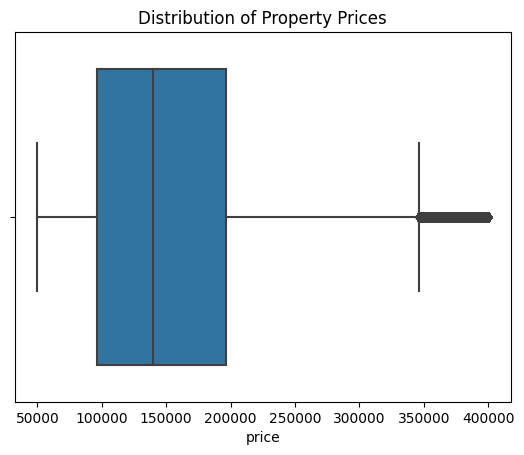

In [39]:
# create box plot to view outliers
sns.boxplot(x=cleaned_final_df['price'])
plt.title('Distribution of Property Prices')
plt.show()

- 50% of the property prices fall between approximately £100,000 and £200,000
- The median appears to be around £150,000, indicating that half of the properties are priced below this value and half are priced above.
- The majority of properties are priced between £100,000 and £200,000, with a few extending to £350,000 and above.
- The data seems to be slightly skewed to the right, as the whisker on the higher end is longer, indicating more variability in higher property prices.
- The presence of potential outliers suggests that there are some properties with prices that are significantly higher than the norm, which could be luxury properties or those in prime locations.

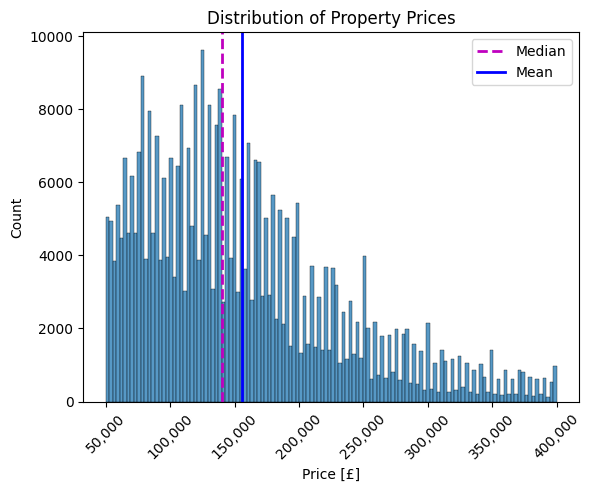

In [40]:
# Create a figure and axes. Then plot the data
fig, ax = plt.subplots()
sns.histplot(cleaned_final_df['price'], ax=ax)

# Customize the labels and limits
ax.set(xlabel="Price [£]",
       title="Distribution of Property Prices")

# Add vertical lines for the median and mean
ax.axvline(x=cleaned_final_df['price'].median(), color='m',
           label='Median', linestyle='--', linewidth=2)
ax.axvline(x=cleaned_final_df['price'].mean(), color='b',
           label='Mean', linestyle='-', linewidth=2)


# after plotting the data, format the labels
current_values = plt.gca().get_xticks()
# using format string '{:.0f}' here but you can choose others
plt.gca().set_xticklabels(['{:,.0f}'.format(x) for x in current_values])

plt.xticks(rotation=45)

# Show the legend and plot the data
ax.legend()
plt.show()

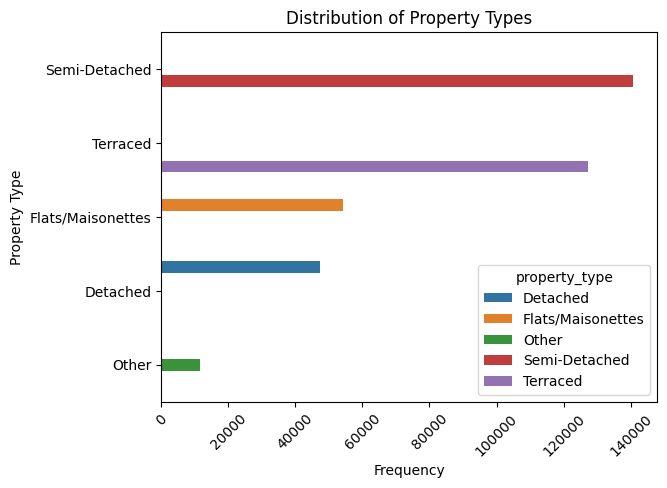

In [41]:
# Create count plot
sns.countplot(y='property_type', data=cleaned_final_df,
              order=cleaned_final_df['property_type'].value_counts().index, hue='property_type')
plt.title('Distribution of Property Types')
plt.xlabel('Frequency')
plt.ylabel('Property Type')
plt.xticks(rotation=45)
# Show plot
plt.show()

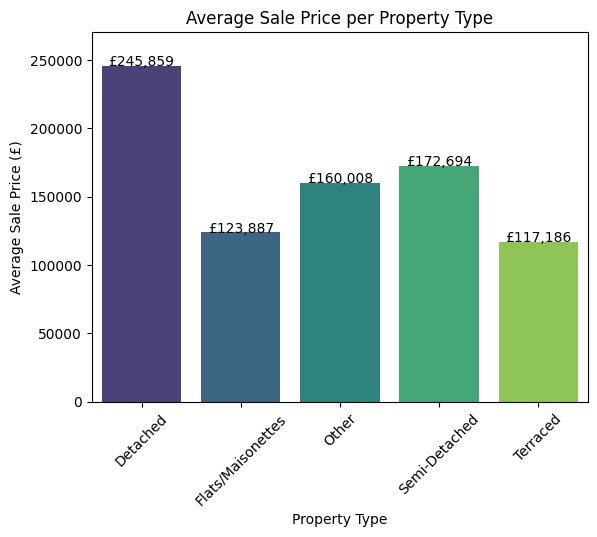

In [42]:
# Calculate the average price per property type
avg_price_per_type = cleaned_final_df.groupby(
    'property_type')['price'].mean().reset_index()

# Create a vertical bar plot
sns.barplot(x='property_type', y='price',
            data=avg_price_per_type, palette='viridis')

# Annotate the bars with the average price values
for index, row in avg_price_per_type.iterrows():
    plt.text(index, row.price, f'£{row.price:,.0f}',
             color='black', ha="center")

# Add title and labels
plt.title('Average Sale Price per Property Type')
plt.xlabel('Property Type')
plt.ylabel('Average Sale Price (£)')
plt.xticks(rotation=45)
# Adjust y-axis to give space for annotations
plt.ylim(0, avg_price_per_type['price'].max() * 1.1)

# Show plot
plt.show()

- The majority of the properties are semi-detached or terraced homes, indicating that these are the most common types of housing available in the Merseyside.
- The relatively lower number of flats/maisonettes and detached houses might suggest a different demographic or housing demand compared to the more common property types.

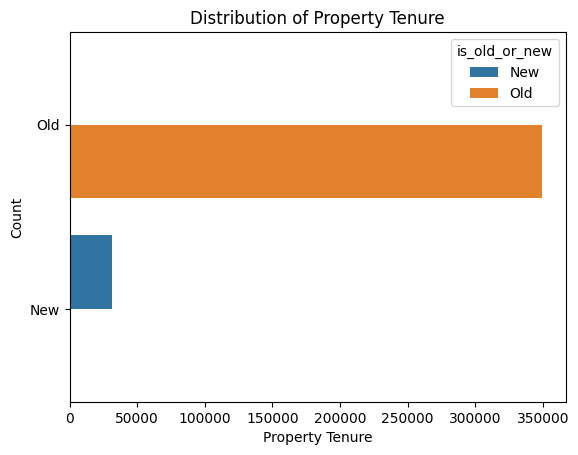

In [43]:
# Create count plot
sns.countplot(y='is_old_or_new', data=cleaned_final_df,
              order=cleaned_final_df['is_old_or_new'].value_counts().index, hue='is_old_or_new')
plt.title('Distribution of Property Tenure')
plt.xlabel('Property Tenure')
plt.ylabel('Count')
# Show plot
plt.show()

- vast majority of the housing market consists of older properties. This could reflect a more mature housing market with less new construction or a higher demand for established homes.

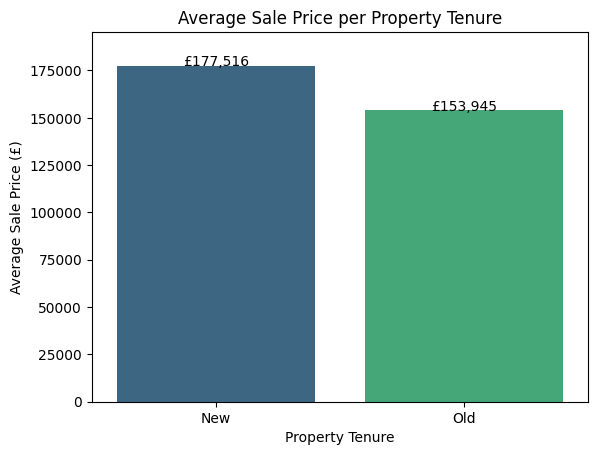

In [44]:
# Calculate the average price per property tenure
avg_price_per_tenure = cleaned_final_df.groupby(
    'is_old_or_new')['price'].mean().reset_index()

# Create a vertical bar plot
sns.barplot(x='is_old_or_new', y='price',
            data=avg_price_per_tenure, palette='viridis')

# Annotate the bars with the average price values
for index, row in avg_price_per_tenure.iterrows():
    plt.text(index, row.price, f'£{row.price:,.0f}',
             color='black', ha="center")

# Add title and labels
plt.title('Average Sale Price per Property Tenure')
plt.xlabel('Property Tenure')
plt.ylabel('Average Sale Price (£)')
# Adjust y-axis to give space for annotations
plt.ylim(0, avg_price_per_tenure['price'].max() * 1.1)

# Show plot
plt.show()

#### Bivariate Analysis

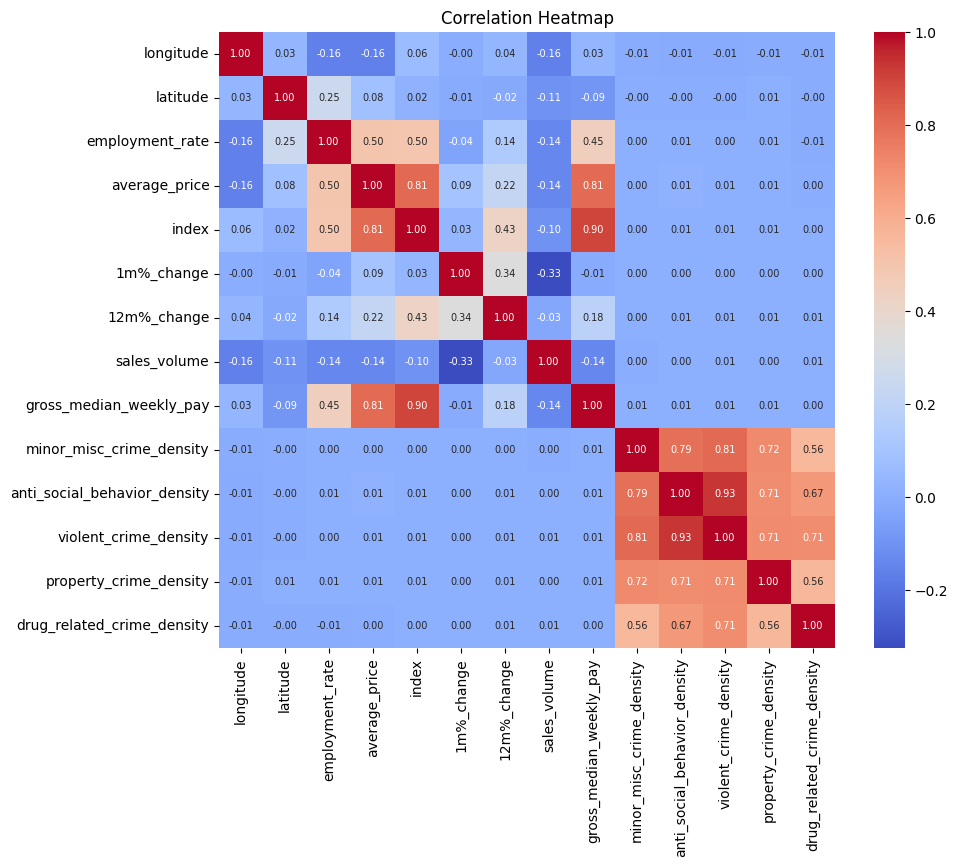

In [45]:
corr = cleaned_final_df.select_dtypes('number').drop(columns='price').corr()
plt.figure(figsize=(10, 8))
sns.heatmap(corr,
            cbar=True,
            annot=True,
            cmap='coolwarm',
            square=True,
            fmt='.2f',
            annot_kws={'size': 7})
plt.title('Correlation Heatmap')
plt.show()

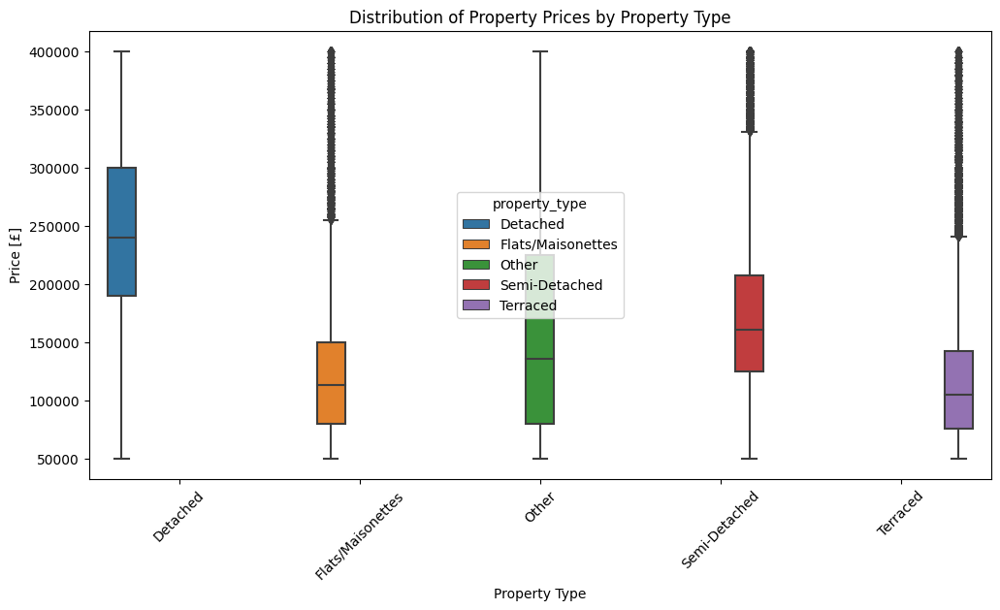

In [46]:
plt.figure(figsize=(12, 6))
sns.boxplot(x='property_type', y='price', data=cleaned_final_df, hue='property_type')
plt.title('Distribution of Property Prices by Property Type')
plt.xlabel('Property Type')
plt.ylabel('Price [£]')
plt.xticks(rotation=45)
plt.show()

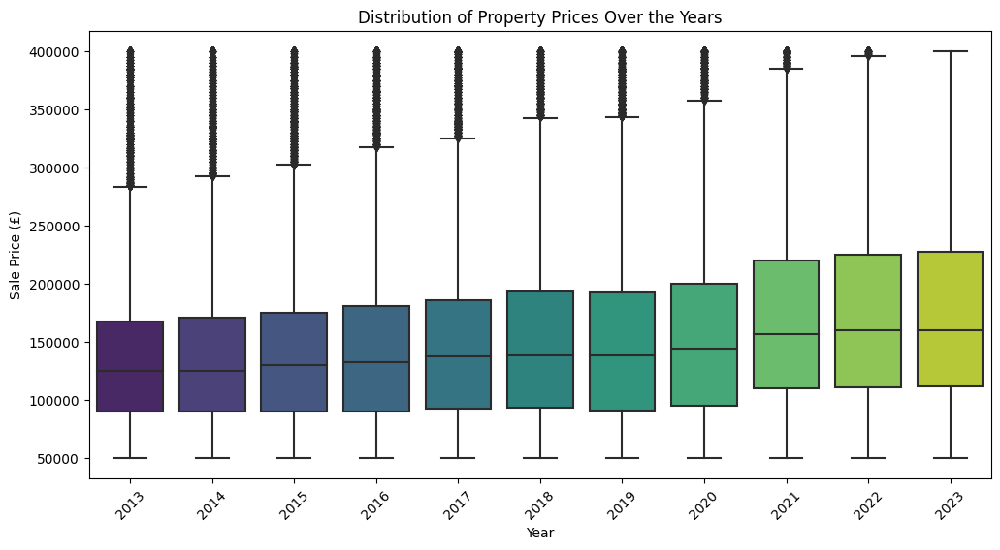

In [47]:
# Create a box plot of property prices across years
plt.figure(figsize=(12, 6))
sns.boxplot(x=cleaned_final_df["transfer_date"].dt.year,
            y='price', data=cleaned_final_df, palette='viridis')

# Add title and labels
plt.title('Distribution of Property Prices Over the Years')
plt.xlabel('Year')
plt.ylabel('Sale Price (£)')
plt.xticks(rotation=45)  # Rotate x-axis labels for better readability

# Show plot
plt.show()

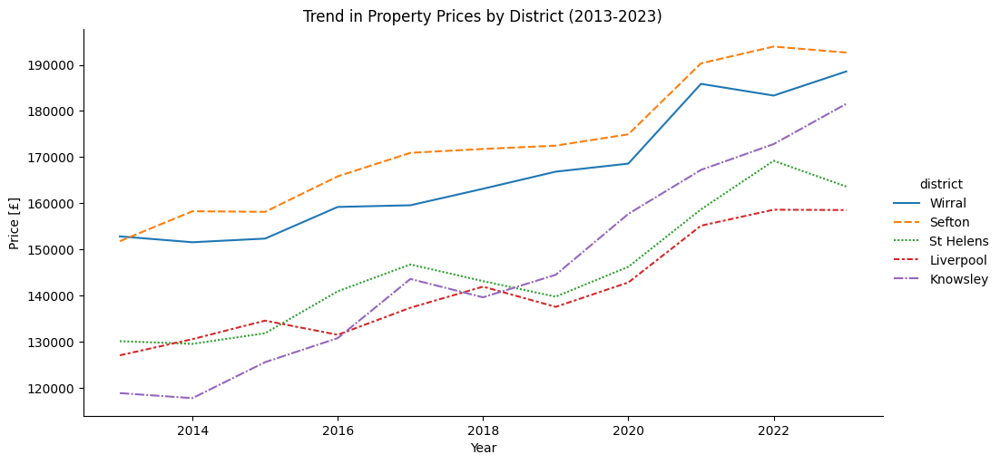

In [48]:
sns.relplot(x=cleaned_final_df["transfer_date"].dt.year, y="price",
            data=cleaned_final_df, kind="line", style='district', hue='district',
            ci=None, aspect=2)
plt.title("Trend in Property Prices by District (2013-2023)")
plt.xlabel('Year')
plt.ylabel('Price [£]')
# Show plot
plt.show()

In [49]:
# Plot Mapbox location and price
fig = px.scatter_mapbox(
    cleaned_final_df,
    lat='latitude',
    lon='longitude',
    color='price',
    hover_data=['town']
)

fig.update_layout(mapbox_style="open-street-map", height = 600, width = 800)

fig.show()

### Split

Given the likely temporal trends in property prices, a time-based split is the best approach for the project. This will ensure that the model is evaluated on its ability to predict future property prices based on past data.

In [50]:
# Sort data by date to ensure it's in chronological order
cleaned_final_df = cleaned_final_df.sort_values(by='transfer_date')

# Define the date to split the data
split_date = '2022-01-01'

# Create train and test sets
train_data = cleaned_final_df[cleaned_final_df['transfer_date'] < split_date]
test_data = cleaned_final_df[cleaned_final_df['transfer_date'] >= split_date]



# Separate features and target variable
X_train = train_data.drop('price', axis=1)
X_test = test_data.drop('price', axis=1)

# Extract year and month from transfer_date
X_train['year'] = X_train['transfer_date'].dt.year
X_train['month'] = X_train['transfer_date'].dt.month
X_test['year'] = X_test['transfer_date'].dt.year
X_test['month'] = X_test['transfer_date'].dt.month

# Drop the original transfer_date column
X_train = X_train.drop('transfer_date', axis=1)
X_test = X_test.drop('transfer_date', axis=1)

y_train = train_data['price']
y_test = test_data['price']

In [51]:
# show shape of train and test data
print(X_train.shape)
print(y_train.shape)
print(X_test.shape)
print(y_test.shape)

(312734, 23)
(312734,)
(68303, 23)
(68303,)


## Build Model

### Baseline

In [52]:
y_mean_log = np.log(y_train).mean()
y_pred_baseline_log = [y_mean_log] * len(y_train)
baseline_mae_log = mean_absolute_error(y_pred_baseline_log, np.log(y_train))
# print(f"Mean property price: £{y_mean_log.round(2)}")
# print(f"Baseline MAE: £{baseline_mae_log.round(2)}")

# Print the results
print(f"Log-transformed mean property price: {y_mean_log}")
print(f"Baseline MAE (log-transformed): {baseline_mae_log}")

# To compare with the MAE from the RandomForest model, you can exponentiate the log baseline MAE
baseline_mae = np.exp(baseline_mae_log)
print(f"Baseline MAE (exponentiated): {baseline_mae}")

Log-transformed mean property price: 11.813557817676493
Baseline MAE (log-transformed): 0.3980025786550652
Baseline MAE (exponentiated): 1.4888478691274267


The results indicate the following:

- Log-transformed mean property price: This value (approximately 11.81) represents the mean property price after applying the logarithmic transformation. The exact numerical value isn't directly interpretable as a price until it's exponentiated back.
- Baseline MAE (log-transformed): This value (approximately 0.398) represents the Mean Absolute Error when predicting the log-transformed mean property price for all properties. This is on the log scale, so it shows the average difference between the log-transformed predictions and the actual log-transformed values.
- Baseline MAE (exponentiated): This value (approximately 1.49) represents the exponentiated baseline MAE, giving you a sense of the error in the original scale of property prices.

Interpretation:
- The exponentiated Baseline MAE is around 1.49, which serves as the benchmark. Any model that you develop should ideally have an MAE lower than this to be considered useful.
- Your Random Forest model's MAE was approximately 0.236 (as per the earlier results), which is better than the baseline MAE of 1.49. This confirms that your model performs better than simply predicting the average log-transformed price for all properties.

### Data pre-processing & Pipeline creation

In [53]:
# Define transformers for numerical and categorical columns
numerical_transformer = Pipeline(
    steps=[
        ('imputer', SimpleImputer(strategy='mean')),
        ('scaler', StandardScaler())
    ]
)

categorical_transformer = Pipeline(
    steps=[
        ('imputer', SimpleImputer(strategy='constant', fill_value='missing')),
        ('onehot', OneHotEncoder(handle_unknown='ignore'))
    ]
)

In [54]:
# create category columns selector
categorical_columns = X_train.select_dtypes(
    include=['object', 'category']).columns
# create numerical columns selector without price
numerical_columns = X_train.select_dtypes(
    include=['int32', 'int64', 'float64']).columns

print(categorical_columns)
print(numerical_columns)

Index(['property_type', 'is_old_or_new', 'property_tenure', 'town', 'district',
       'ppd_transaction_category', 'flood_proximity'],
      dtype='object')
Index(['longitude', 'latitude', 'employment_rate', 'average_price', 'index',
       '1m%_change', '12m%_change', 'sales_volume', 'gross_median_weekly_pay',
       'minor_misc_crime_density', 'anti_social_behavior_density',
       'violent_crime_density', 'property_crime_density',
       'drug_related_crime_density', 'year', 'month'],
      dtype='object')


In [55]:
# combine transformers
preprocessor = ColumnTransformer(
    transformers=[
        ('numerical', numerical_transformer, numerical_columns),
        ('categorical', categorical_transformer, categorical_columns)
    ], remainder='passthrough' #all data is going in and out, not just returning columns we transformed
)

In [56]:
# create pipeline with preprocessor
pipeline = Pipeline(
    steps=[
        ('preprocessor', preprocessor)
    ]
)

In [57]:
# applying pipeline to data
X_train_preprocessed = pipeline.fit_transform(X_train)
X_test_preprocessed = pipeline.transform(X_test)


# normalised dependent variable because of skewness
y_train_preprocessed = np.log(y_train)
y_test_preprocessed = np.log(y_test)

### Model training

In [58]:
# define models
models = {
    'LinearRegression': LinearRegression(),
    'RandomForest': RandomForestRegressor(random_state=42),
    'GradientBoosting': GradientBoostingRegressor(random_state=42),
    'XGBoost': XGBRegressor(random_state = 42)
}

In [59]:
# define hyperparameters for each model
params_grid = {
    'LinearRegression': {},
    'RandomForest': {
        'n_estimators': [100, 200, 500],
        'max_depth': [None, 10, 20, 30],
        'min_samples_split': [2, 5, 10]
    },
    'GradientBoosting': {
        'n_estimators': [100, 200, 500],
        'learning_rate': [0.01, 0.05, 0.1, 0.2],
        'max_depth': [3, 4, 5, 6]
    },
    'XGBoost': {
        'n_estimators': [100, 200, 500],
        'learning_rate': [0.01, 0.05, 0.1, 0.2],
        'max_depth': [3, 4, 5, 6]
    }
}


# 5-fold cross validation
cv = KFold(n_splits=5, shuffle=True, random_state=42)

In [60]:
# custom scoring function
scoring = {
    'MAE': make_scorer(mean_absolute_error, greater_is_better=False),
    'RMSE': make_scorer(mean_squared_error, greater_is_better=False, squared=False),
    'R2': make_scorer(r2_score, greater_is_better=True)
}


# train and tune model
grids = {}
for model_name, model in models.items():
    # Create the GridSearchCV object for each model
    grids[model_name] = GridSearchCV(
        estimator=model,
        param_grid=params_grid[model_name],
        cv=cv,
        scoring=scoring,
        refit='MAE',  # Choose 'MAE' as the primary metric for refitting
        return_train_score=True,
        n_jobs=-1  # Use all available cores for parallel processing
    )

    # Fit the model
    grids[model_name].fit(X_train_preprocessed, y_train_preprocessed)

    # Get the best parameters and scores
    best_params = grids[model_name].best_params_
    best_mae = -1 * grids[model_name].best_score_
    best_rmse = np.sqrt(-1 * grids[model_name].cv_results_[
                        'mean_test_RMSE'][grids[model_name].best_index_])
    best_r2 = grids[model_name].cv_results_[
        'mean_test_R2'][grids[model_name].best_index_]

    # Print the results
    print(f'Best parameters for {model_name}: {best_params}')
    print(f'Best MAE for {model_name}: {best_mae}')
    print(f'Best RMSE for {model_name}: {best_rmse}')
    print(f'Best R2 for {model_name}: {best_r2}\n')

Best parameters for LinearRegression: {}
Best MAE for LinearRegression: 114866.55123097307
Best RMSE for LinearRegression: 5359.786258745245
Best R2 for LinearRegression: -7956697077649829.0

Best parameters for RandomForest: {'max_depth': None, 'min_samples_split': 5, 'n_estimators': 500}
Best MAE for RandomForest: 0.10400246709566756
Best RMSE for RandomForest: 0.42517182404115544
Best R2 for RandomForest: 0.8614211942134193

Best parameters for GradientBoosting: {'learning_rate': 0.2, 'max_depth': 6, 'n_estimators': 500}
Best MAE for GradientBoosting: 0.15605112725920434
Best RMSE for GradientBoosting: 0.4615768416196665
Best R2 for GradientBoosting: 0.8075131934188514

Best parameters for XGBoost: {'learning_rate': 0.2, 'max_depth': 6, 'n_estimators': 500}
Best MAE for XGBoost: 0.15724764539328442
Best RMSE for XGBoost: 0.46309944073983694
Best R2 for XGBoost: 0.8049619708483299



### Model evaluation

In [61]:
# Train the RandomForest model with the best hyperparameters
best_rf_model = RandomForestRegressor(
    n_estimators=500,
    max_depth=None,
    min_samples_split=5,
    random_state=42,
    n_jobs=-1
)

# Fit the model on the entire training data
best_rf_model.fit(X_train_preprocessed, y_train_preprocessed)

RandomForestRegressor(min_samples_split=5, n_estimators=500, n_jobs=-1,
                      random_state=42)

In [62]:
# Make predictions on the test set
y_pred = best_rf_model.predict(X_test_preprocessed)

In [63]:
# Make predictions on the test set

# Calculate MAE
mae = mean_absolute_error(y_test_preprocessed, y_pred)

# Calculate RMSE
rmse = np.sqrt(mean_squared_error(y_test_preprocessed, y_pred))

# Calculate R-squared (R²)
r2 = r2_score(y_test_preprocessed, y_pred)

# Print the results
print(f"Mean Absolute Error (MAE): {mae}")
print(f"Root Mean Squared Error (RMSE): {rmse}")
print(f"R-squared (R²): {r2}")

Mean Absolute Error (MAE): 0.23601009885209226
Root Mean Squared Error (RMSE): 0.3041306722483079
R-squared (R²): 0.5881524977068298


Interpretation:
- MAE gives the average absolute difference between the predicted and actual values. An MAE of 0.236 means that, on average, the model's predictions are off by approximately 23.6% ( since the target (price) was scaled/normalised).
- RMSE penalizes larger errors more than MAE because it squares the errors before averaging them. An RMSE of 0.304 indicates that the model has some larger errors, but generally, it suggests a reasonably good fit, since it is close to the MAE.

## Communicate results

In [64]:
# define model coefficients
importances = best_rf_model.feature_importances_

# get feature names
features = pipeline.named_steps['preprocessor'].get_feature_names_out()

# define feature importance series
feat_imp = pd.Series(importances, index=features).sort_values(key=abs)
print(feat_imp.head())

categorical__flood_proximity_5.0    0.000000e+00
categorical__town_Coniston          2.462667e-09
categorical__town_Winsford          1.159610e-08
categorical__town_Crewe             1.592390e-08
categorical__town_Northwood         2.354585e-07
dtype: float64


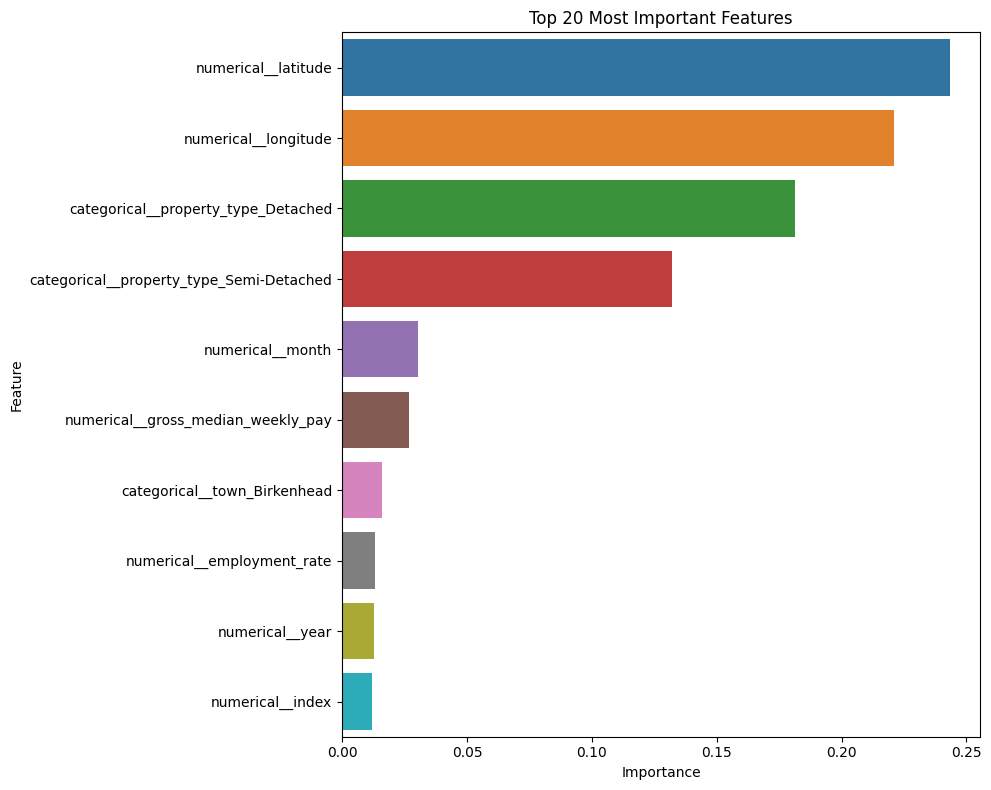

In [65]:
# Combine the feature names and their corresponding importances
feature_importance_df = pd.DataFrame(
    {'Feature': features, 'Importance': importances})

# Sort the features by importance
feature_importance_df = feature_importance_df.sort_values(
    by='Importance', ascending=False)

# Plot feature importances
plt.figure(figsize=(10, 8))
sns.barplot(x='Importance', y='Feature',
            data=feature_importance_df.head(10))  # Plot top 10 features
plt.title('Top 10 Most Important Features')
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

## Save Model

In [66]:
# save pipeline
# Combine the preprocessor and the model into a single pipeline
final_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', best_rf_model)
])

# Save the entire pipeline
with open("final_model_pipeline.pkl", "wb") as f:
    pickle.dump(final_pipeline, f)